# Phase 2 — Train a Small Model and Evaluate It
**Building LLM Systems · Team Project · ABCD customer-support data (AcmeCorp)**

This notebook contains **all the code** of Phase 2, in order. Every section produces one of the deliverables
required by the brief:

| § | Section | Deliverable |
|---|---|---|
| 0 | Setup and configuration | reproducible settings (fixed seed, all hyper-parameters in one place) |
| 1 | Continued-pretraining corpus | cleaned text, 90/10 split by document, size in tokens |
| 2 | Test set and SFT pairs | 30 test cases, SFT pairs, **no-overlap check**, hand-check sheet |
| 3 | Prompt template, generation, scoring | one function to call every model, one scoring method |
| 4 | Base model | held-out perplexity, sample completions, test answers |
| 5 | Stage 1 — continued pretraining | loss curves, perplexity before → after, checkpoints |
| 6 | Stage 2 — supervised fine-tuning | answer-only loss, loss curves, checkpoints |
| 7 | Scoreboard | one row per version + the same questions answered by all three models |
| 8 | Human grading | blind sheets, agreement + Cohen's κ, settled disagreements |
| 9 | Error analysis | every wrong SFT answer sorted into one cause |
| 10 | Save | results archive, optional upload to the Hugging Face Hub |

**How to run (Kaggle):** *Settings → Accelerator: GPU T4* and *Internet: On*; *Add Input* → the project dataset
(the folder that contains `data/guidelines.json`). Then *Run All*. Full run ≈ 40–60 min on one T4.
Set `QUICK_TEST = True` first to check the whole pipeline in a few minutes (5% of the data, few steps).

## 0. Setup and configuration
One GPU is used on purpose (Kaggle sometimes gives two T4s; using one keeps runs reproducible).
Every setting of the project lives in `CFG`.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gzip, json, math, random, re, shutil, time, unicodedata, urllib.request, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import transformers
from transformers import (AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments,
                          TrainerCallback, EarlyStoppingCallback, StoppingCriteria, StoppingCriteriaList)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 160)
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

torch 2.11.0+cu130 | transformers 5.20.2 | GPU: Tesla T4


In [2]:
QUICK_TEST = False          # True = pipeline test on 5% of the data with a few training steps

CFG = {
    "seed": 42,
    "base_model": os.environ.get("BASE_MODEL", "HuggingFaceTB/SmolLM2-135M"),   # allowed by the brief
    "data": {
        "heldout_frac": 0.10,        # held-out documents for perplexity (never trained on)
        "val_frac": 0.05,            # validation documents for the loss curve and early stopping
        "policy_upsample": 5,        # guideline + handbook documents repeated in TRAIN only
        "max_dialogues": None,       # None = all 10,042 ABCD conversations
    },
    "cpt": {"block_size": 512, "epochs": 3, "lr": 1e-4, "batch_size": 8, "grad_accum": 2,
            "warmup_ratio": 0.05, "weight_decay": 0.01, "eval_steps": 50, "patience": 3},
    "sft": {"epochs": 4, "lr": 5e-5, "batch_size": 8, "grad_accum": 1, "max_len": 512,
            "warmup_ratio": 0.05, "weight_decay": 0.0, "eval_steps": 10, "patience": 4, "val_frac": 0.10},
    "gen": {"max_new_tokens": 128, "repetition_penalty": 1.0},   # greedy; identical for all models
}
if QUICK_TEST:
    CFG["data"]["max_dialogues"] = 500
    CFG["cpt"].update(epochs=1, eval_steps=10)
    CFG["sft"].update(epochs=1, eval_steps=10)
MAX_STEPS = 30 if QUICK_TEST else -1


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)

set_seed(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Project folder (read-only on Kaggle) and working folder (all outputs go here)
def find_project():
    for root in [Path.cwd(), Path.cwd().parent, Path("/kaggle/input")]:
        for p in [root] + sorted(root.glob("**/data/guidelines.json"))[:5]:
            p = p if p.name != "guidelines.json" else p.parent.parent
            if (p / "data" / "guidelines.json").exists():
                return p
    raise FileNotFoundError("Add the project dataset (folder with data/guidelines.json) as input.")

PROJECT = find_project()
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd() / "work"
for sub in ["data", "results", "results/grading", "checkpoints", "figures"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
RES, FIG, CKPT = WORK / "results", WORK / "figures", WORK / "checkpoints"
print("project:", PROJECT, "\nworking folder:", WORK)

project: /kaggle/input/datasets/nooraliattoun/abcd-phase22/abcd-phase2-final 
working folder: /kaggle/working


## 1. Continued-pretraining corpus
**Sources** (all from the ABCD v1.1 release, Phase 1 data card):
1. `guidelines.json` — 55 subflow guidelines → one document each;
2. `kb.json` — the action sequence of every subflow → one document;
3. the 10,042 ABCD conversations → one document each, as `Customer: / Agent: / Action:` lines;
4. a short **policy handbook** (one clean summary per subflow, written from the guidelines; `tools/handbook.py`).

**Cleaning:** Unicode normalised, whitespace collapsed, empty turns dropped, exact duplicates removed, and personal
fields in conversations (names, e-mails, phones, usernames, account/order IDs, PINs, addresses, zip codes) replaced by
placeholders such as `<name>` — the data is synthetic, but the model should not memorise personal-looking strings.

**Split by document:** 10% held out (perplexity only), 5% validation (loss curve + early stopping), the rest train.
Product Defect guideline documents and the handbook stay in train (the test questions are about them).
Policy documents are repeated ×5 in **train only**, so the rules are seen more often than once among 10k dialogues.

In [3]:
ABCD_URL = "https://raw.githubusercontent.com/asappresearch/abcd/master/data/abcd_v1.1.json.gz"
_ASCII = {"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": "-",
          "→": "->", "…": "...", " ": " "}

def clean_text(text):
    text = unicodedata.normalize("NFKC", text)
    for k, v in _ASCII.items():
        text = text.replace(k, v)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    return re.sub(r"\n{3,}", "\n\n", text).strip()

def guideline_documents(guidelines):
    docs = []
    for flow, fv in guidelines.items():
        for sub, sv in fv["subflows"].items():
            lines = ["AcmeCorp customer support guidelines.", f"Flow: {flow} ({fv['description']}). Subflow: {sub}."]
            instr = [i.strip() + ("" if i.strip()[-1:] in ".:!?" else ".") for i in sv.get("instructions", []) if i.strip()]
            if instr:
                lines.append("Instructions: " + " ".join(instr))
            for n, a in enumerate(sv["actions"], 1):
                text = a["text"].strip() if a["text"].strip().lower() not in ("x", "") else f"Use [{a['button']}]."
                lines.append(f"Step {n} - {a['button']} ({a['type']}): {text}")
                lines += ["- " + s.replace("<or>", "or").replace(" > ", ": ").replace("> ", "").strip() for s in a["subtext"]]
            docs.append({"source": "guideline", "flow": flow, "subflow": sub, "text": clean_text("\n".join(lines))})
    return docs

def kb_document(kb):
    lines = ["AcmeCorp support knowledge base: the actions an agent takes, in order, for each subflow."]
    lines += [f"{s.replace('_', ' ')}: " + ", then ".join(a.replace("-", " ") for a in acts) + "." for s, acts in kb.items()]
    return {"source": "kb", "flow": "All", "subflow": "action sequences", "text": "\n".join(lines)}

PII_FIELDS = [("order", "full_address", "<address>"), ("order", "street_address", "<street address>"),
              ("personal", "email", "<email>"), ("personal", "customer_name", "<name>"),
              ("personal", "username", "<username>"), ("personal", "account_id", "<account id>"),
              ("personal", "phone", "<phone>"), ("personal", "pin_number", "<pin>"),
              ("personal", "security_answer", "<security answer>"), ("personal", "password", "<password>"),
              ("order", "order_id", "<order id>"), ("order", "zip_code", "<zip code>")]
GENERIC_PII = [(re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"), "<email>"),
               (re.compile(r"\(?\d{3}\)?[ .-]?\d{3}[ .-]?\d{4}"), "<phone>"),
               (re.compile(r"\b\d{9,}\b"), "<number>"),
               (re.compile(r"\b(?=[A-Z0-9]*\d)(?=[A-Z0-9]*[A-Z])[A-Z0-9]{10}\b", re.I), "<id>")]

def scrub(text, scenario):
    """Replace this conversation's personal values (known from its scenario) and any generic e-mail/phone/ID."""
    pairs = [(str(scenario.get(sec, {}).get(k) or "").strip(), ph) for sec, k, ph in PII_FIELDS]
    pairs += [(part, "<name>") for part in str(scenario.get("personal", {}).get("customer_name") or "").split()]
    for val, ph in sorted([p for p in pairs if len(p[0]) >= 3], key=lambda p: -len(p[0])):
        text = re.sub(r"(?<!\w)" + re.escape(val) + r"(?!\w)", ph, text, flags=re.I)
    for rx, ph in GENERIC_PII:
        text = rx.sub(ph, text)
    return re.sub(r"(<name>)(\s+<name>)+", r"\1", text)

ROLE_LABEL = {"agent": "Agent", "customer": "Customer", "action": "Action"}

def dialogue_document(convo):
    sc = convo["scenario"]
    lines = [f"Customer support conversation. Flow: {sc['flow'].replace('_', ' ')}. Subflow: {sc['subflow'].replace('_', ' ')}."]
    for speaker, utt in convo["original"]:
        utt = clean_text(scrub(utt, sc))
        if utt:
            lines.append(f"{ROLE_LABEL.get(speaker, speaker.title())}: {utt}")
    return {"source": "dialogue", "flow": sc["flow"], "subflow": sc["subflow"], "text": "\n".join(lines)}

# --- load the raw data
guidelines = json.load(open(PROJECT / "data/guidelines.json"))
kb = json.load(open(PROJECT / "data/kb.json"))
raw_path = WORK / "data/abcd_v1.1.json.gz"
if not raw_path.exists():
    local = PROJECT / "data/raw/abcd_v1.1.json.gz"
    if local.exists():
        shutil.copy(local, raw_path)
    else:
        print("downloading ABCD v1.1 from GitHub ..."); urllib.request.urlretrieve(ABCD_URL, raw_path)
abcd = json.load(gzip.open(raw_path, "rt"))
convos = sorted((c for split in ("train", "dev", "test") for c in abcd[split]), key=lambda c: c["convo_id"])
if CFG["data"]["max_dialogues"]:
    convos = random.Random(CFG["seed"]).sample(convos, CFG["data"]["max_dialogues"])
handbook = [json.loads(l) for l in open(PROJECT / "data/policy_handbook.jsonl")]

docs = guideline_documents(guidelines) + [kb_document(kb)] + [dialogue_document(c) for c in convos]
seen, unique = set(), []
for d in docs:                                   # exact-duplicate removal
    if d["text"].lower() not in seen:
        seen.add(d["text"].lower()); unique.append(d)
print(f"{len(docs)} documents -> {len(unique)} after removing {len(docs) - len(unique)} exact duplicates")
print("\nExample of a cleaned conversation:\n" + unique[-1]["text"][:700])

downloading ABCD v1.1 from GitHub ...
10098 documents -> 10098 after removing 0 exact duplicates

Example of a cleaned conversation:
Customer support conversation. Flow: purchase dispute. Subflow: promo code invalid.
Agent: Hello, and how may I help you tonight?
Customer: Hi, my promo code isn't working!
Agent: No problem, let's see what's going on here
Agent: To whom do I have the pleasure of speaking with?
Customer: <name>
Action: Account has been pulled up for <name>.
Agent: Good evening <name>, my name is Richard and I'd be happy to help you with your promo code issue
Agent: So to start, promo codes usually last for a week
Agent: How long have you had yours for
Customer: I've had this promo code 5 days ago
Customer: should still be valid
Agent: Let me check the system about this situation
Action: Querying the system f


In [4]:
def split_documents(docs, seed):
    """90/10 by document, stratified (policy documents and dialogues split separately).
    Product Defect guidelines are pinned to train; a further 5% of training dialogues becomes the validation set."""
    rng = random.Random(seed)
    train, val, held = [], [], []
    policy = [d for d in docs if d["source"] != "dialogue"]
    dialogues = [d for d in docs if d["source"] == "dialogue"]
    free = [d for d in policy if d["flow"] != "Product Defect"]
    rng.shuffle(free)
    n_held = round(CFG["data"]["heldout_frac"] * len(policy))
    held += free[:n_held]; train += [d for d in policy if d not in held]
    rng.shuffle(dialogues)
    n_held, n_val = round(CFG["data"]["heldout_frac"] * len(dialogues)), round(CFG["data"]["val_frac"] * len(dialogues))
    held += dialogues[:n_held]; val += dialogues[n_held:n_held + n_val]; train += dialogues[n_held + n_val:]
    return train, val, held

train_docs, val_docs, held_docs = split_documents(unique, CFG["seed"])
policy_train = [d for d in train_docs if d["source"] != "dialogue"] + handbook
train_texts = [d["text"] for d in train_docs if d["source"] == "dialogue"] + [d["text"] for d in policy_train] * CFG["data"]["policy_upsample"]
random.Random(CFG["seed"]).shuffle(train_texts)
val_texts, held_texts = [d["text"] for d in val_docs], [d["text"] for d in held_docs]

for name, rows in [("train", train_docs), ("validation", val_docs), ("heldout", held_docs)]:
    with open(WORK / f"data/cpt_{name}.jsonl", "w") as f:
        for r in rows: f.write(json.dumps(r) + "\n")
(WORK / "data/cpt_sample_train.txt").write_text("\n\n".join(t for t in train_texts[:200]))

tokenizer = AutoTokenizer.from_pretrained(CFG["base_model"])
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
count = lambda texts: sum(len(tokenizer(t, add_special_tokens=False)["input_ids"]) + 1 for t in texts)
corpus_stats = pd.DataFrame([
    {"split": "train (unique documents)", "documents": len(train_docs) + len(handbook), "tokens": count([d["text"] for d in train_docs] + [d["text"] for d in handbook])},
    {"split": f"train (policy docs x{CFG['data']['policy_upsample']})", "documents": len(train_texts), "tokens": count(train_texts)},
    {"split": "validation (early stopping)", "documents": len(val_docs), "tokens": count(val_texts)},
    {"split": "held-out 10% (perplexity)", "documents": len(held_docs), "tokens": count(held_texts)},
])
corpus_stats.to_csv(RES / "corpus_stats.csv", index=False)
corpus_stats

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

,split,documents,tokens
0,train (unique documents),8628,2565680
1,train (policy docs x5),8996,2658960
2,validation (early stopping),502,150862
3,held-out 10% (perplexity),1010,302157


## 2. Test set and SFT pairs
**Test set** — our 30 Phase 1 cases (`tests/test_questions.csv`, v2): 12 short answers scored by exact match,
18 longer answers graded by hand; 6 cases must be refused.

**SFT pairs** — `data/sft_pairs.jsonl`, written from the guidelines and checked by hand
(sheet exported below). Answers are written as the AcmeCorp agent would reply. They cover all 55 subflows:
conversation openers that ask for the full name / account ID, policy facts, membership scenarios, multi-turn
follow-ups, a summary of every subflow's guideline, and refusals (out of scope, undocumented, live account data,
guarantees).

**No overlap with the test set:** no SFT question may copy or paraphrase a test question. We check exact matches and
character-n-gram TF-IDF similarity, and we list the nearest SFT question for every test question for a manual audit.

In [5]:
tests = pd.read_csv(PROJECT / "tests/test_questions.csv", keep_default_na=False)
override = sorted(Path("/kaggle/input").glob("**/sft_pairs_v3.jsonl"))   # newer pairs uploaded on their own
pairs_path = override[0] if override else PROJECT / "data/sft_pairs.jsonl"
pairs = [json.loads(l) for l in open(pairs_path)]
print("SFT pairs file:", pairs_path)
print(f"{len(tests)} test cases:", dict(Counter(tests.expected_action)), "| scored by:", dict(Counter(tests.answer_type)))
print(f"{len(pairs)} SFT pairs:", dict(Counter(p["category"] for p in pairs)))

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^a-z0-9$ ]", " ", s.lower())).strip()
test_q = [norm(q) for q in tests.customer_input]
sft_q = [norm(p["question"]) for p in pairs]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(test_q + sft_q)
sim = cosine_similarity(vec.transform(test_q), vec.transform(sft_q))
audit = pd.DataFrame({"test_id": tests.test_id, "test_question": tests.customer_input,
                      "nearest_sft_question": [pairs[j]["question"] for j in sim.argmax(1)],
                      "cosine": sim.max(1).round(3)}).sort_values("cosine", ascending=False)
audit.to_csv(RES / "sft_test_overlap_audit.csv", index=False)
exact = set(test_q) & set(sft_q)
print(f"exact matches: {len(exact)} | highest similarity: {audit.cosine.max():.3f} (threshold 0.60)")
assert not exact and audit.cosine.max() < 0.60, "an SFT question is too close to a test question"
audit.head(10)

SFT pairs file: /kaggle/input/datasets/nooraliattoun/abcd-phase22/abcd-phase2-final/data/sft_pairs.jsonl
30 test cases: {'CLARIFY': 4, 'ABSTAIN': 6, 'ANSWER': 20} | scored by: {'judged': 18, 'exact': 12}
591 SFT pairs: {'abstain_guarantee': 22, 'handbook': 84, 'fact': 147, 'scenario': 77, 'abstain_undocumented': 58, 'clarify': 66, 'abstain_out_of_scope': 63, 'multiturn': 36, 'direct': 28, 'abstain_live_data': 10}
exact matches: 0 | highest similarity: 0.543 (threshold 0.60)


,test_id,test_question,nearest_sft_question,cosine
11,SP-12,Which refund status labels are in the support guidelines?,Summarize the AcmeCorp support guideline for: Refund Status.,0.543
3,SP-04,I want to check my refund status.,What does a subscription status check show?,0.518
24,SP-25,Will the company definitely cover the shipping cost?,Will the price definitely drop again next week?,0.437
9,SP-10,I want a refund but I don't know the dollar amount. What amount is used by default?,"If my account credit is missing and I don't know the amount, how much do you add back?",0.426
26,SP-27,Can you guarantee the money will reach my bank tomorrow?,Can you guarantee the website will be fixed today?,0.407
12,SP-13,What information is needed to validate a purchase for a refund-status check?,"If you place the order for me, what information do you need?",0.396
8,SP-09,I already have a $100 refund open and I want to add a $30 item to it. What will the total refund be?,How does AcmeCorp handle this case: Update Refund (add an item to an existing refund)?,0.389
4,SP-05,Does Gold membership have a limit on the number of returns?,How long does a membership last?,0.370
6,SP-07,"When I start a refund, which refund methods can I choose from?",Which payment methods can I have on my account?,0.361
0,SP-01,My jeans arrived in the wrong size. Can you help me return them?,"How does AcmeCorp handle this case: Returns (stained item, wrong color or wrong size)?",0.355


In [6]:
# Hand-check sheet: 60 pairs, stratified by category (the brief asks for at least 50 checked by hand)
rng = random.Random(CFG["seed"])
by_cat = {}
for p in pairs:
    by_cat.setdefault(p["category"], []).append(p)
sample = [x for cat, items in sorted(by_cat.items()) for x in rng.sample(items, min(len(items), max(3, round(60 * len(items) / len(pairs)))))]
rng.shuffle(sample); sample = sorted(sample[:60], key=lambda p: p["id"])
pd.DataFrame([{"id": p["id"], "category": p["category"],
               "history": " || ".join(f"{t['role']}: {t['text']}" for t in p["history"]),
               "question": p["question"], "answer": p["answer"], "correct (yes/no)": "", "reviewer": "", "note": ""}
              for p in sample]).to_excel(RES / "sft_hand_check.xlsx", index=False)
print(f"hand-check sheet with {len(sample)} pairs -> {RES / 'sft_hand_check.xlsx'}")

hand-check sheet with 60 pairs -> /kaggle/working/results/sft_hand_check.xlsx


## 3. Prompt template, generation and scoring
**One template for every model and every stage** — the same format as the ABCD conversations used for continued
pretraining, so the domain-trained model already "knows" whose turn it is:
```
Customer support conversation.
Customer: <earlier customer turn>          (only for multi-turn cases)
Agent: <earlier agent turn>
Customer: <question>
Agent: <answer><eos>
```
The SFT target is the answer plus the end-of-sequence token, so the fine-tuned model learns to stop.

**One generation function** (`generate_answer`) for all three models: greedy decoding (temperature 0), at most
128 new tokens, the same stop rule (end-of-sequence, or the start of a new `Customer:` / `Agent:` / `Action:` line).

In [9]:
HEADER = "Customer support conversation."
STOP_STRINGS = ["\nCustomer:", "\nAgent:", "\nAction:"]

def parse_history(raw):
    """'Customer: ...\\nAssistant: ...' (test CSV) -> [{'role': 'user'|'assistant', 'text': ...}]"""
    turns = []
    for line in str(raw or "").splitlines():
        line = line.strip()
        if line.lower().startswith("customer:"):
            turns.append({"role": "user", "text": line.split(":", 1)[1].strip()})
        elif line.lower().startswith(("assistant:", "agent:")):
            turns.append({"role": "assistant", "text": line.split(":", 1)[1].strip()})
        elif line and turns:
            turns[-1]["text"] += " " + line
    return turns

def build_prompt(history, question):
    lines = [HEADER] + [("Customer: " if t["role"] == "user" else "Agent: ") + t["text"] for t in history]
    return "\n".join(lines + [f"Customer: {question}", "Agent:"])

class StopOnStrings(StoppingCriteria):
    def __init__(self, tok, start):
        self.tok, self.start = tok, start
    def __call__(self, input_ids, scores, **kw):
        return any(s in self.tok.decode(input_ids[0, self.start:]) for s in STOP_STRINGS)

def clean_answer(text):
    for s in STOP_STRINGS:
        text = text.split(s)[0]
    return text.strip()

@torch.no_grad()
def generate_answer(model, tok, history, question):
    """THE function used to call every model (base, continued-pretrained, SFT)."""
    ids = tok(build_prompt(history, question), return_tensors="pt")["input_ids"].to(model.device)
    t0 = time.perf_counter()
    out = model.generate(ids, attention_mask=torch.ones_like(ids), do_sample=False, num_beams=1,
                         max_new_tokens=CFG["gen"]["max_new_tokens"], repetition_penalty=CFG["gen"]["repetition_penalty"],
                         eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id,
                         stopping_criteria=StoppingCriteriaList([StopOnStrings(tok, ids.shape[1])]))
    if model.device.type == "cuda":
        torch.cuda.synchronize()
    new = out[0, ids.shape[1]:]
    raw = tok.decode(new, skip_special_tokens=True)
    stopped = (len(new) > 0 and int(new[-1]) == tok.eos_token_id) or any(s in raw for s in STOP_STRINGS)
    return {"answer": clean_answer(raw), "raw": raw, "latency_s": time.perf_counter() - t0,
            "new_tokens": int(len(new)), "stopped": bool(stopped)}

**Scoring (identical for all models).**
* *Exact cases* (yes/no or a number): normalise case and spaces, take the first word (or first number) of the answer
  and compare it with `gold_short`.
* *Refusal cases*: 1 if the model declines, else 0.
* *Longer answers*: graded **by hand** by two team members (§8). Until then a transparent provisional rubric is used:
  every key point of the test case must appear (1), at least half (0.5), otherwise 0; an invented approval or status
  from the `forbidden` list gives 0.

In [10]:
REFUSAL_RX = re.compile("|".join([
    r"i (do not|don't) have (that|this) information", r"outside what acmecorp", r"not in (our|the) (support )?guidelines",
    r"\b(cannot|can't|can not|unable to|not able to) (promise|guarantee|confirm|determine|look up|access|see|check|say)",
    r"\b(is|are) not (specified|documented|covered)", r"\b(does|do) not (specify|say|state|cover)"]), re.I)
is_refusal = lambda a: bool(REFUSAL_RX.search(a or ""))

def predicted_action(answer):
    if is_refusal(answer):
        return "ABSTAIN"
    if "?" in answer and re.search(r"full name|account id|username|order id|email|address", answer, re.I):
        return "CLARIFY"
    return "ANSWER" if answer.strip() else "NONE"

def short_answer(answer, gold):
    body = re.sub(r"\s+", " ", answer.lower()).strip()
    if all(re.fullmatch(r"\d+(\.\d+)?", g.strip()) for g in gold.split("|")):
        m = re.search(r"\$?\s*(\d+(?:\.\d+)?)", body)
        return m.group(1) if m else ""
    m = re.match(r"[a-z']+", body)
    return m.group(0) if m else ""

def score_case(case, answer):
    if case["should_refuse"] == "yes":
        ok = is_refusal(answer)
        return float(ok), "declined" if ok else "should have declined"
    if case["answer_type"] == "exact":
        got = short_answer(answer, case["gold_short"])
        return float(got in [g.strip() for g in case["gold_short"].split("|")]), f"short answer '{got}' vs '{case['gold_short']}'"
    body = answer.lower()
    groups = [g for g in case["key_points"].split(";") if g.strip()]
    missing = [g for g in groups if not any(alt.strip() and alt.strip() in body for alt in g.split("|"))]
    cover = 1 - len(missing) / max(len(groups), 1)
    forbidden = [f for f in case["forbidden"].split("|") if f.strip() and f.strip() in body]
    s = 0.0 if forbidden else 1.0 if cover == 1 else 0.5 if cover >= 0.5 else 0.0
    note = "; ".join(filter(None, ["forbidden: " + ", ".join(forbidden) if forbidden else "",
                                   "missing: " + ", ".join(m.split("|")[0] for m in missing) if missing else ""]))
    return s, "provisional rubric" + (f" ({note})" if note else "")

def run_test_set(name, model, tok):
    """Answer all test questions with one model and save results/results_<name>.csv"""
    model.eval()
    rows = []
    for _, c in (tests.head(5) if QUICK_TEST else tests).iterrows():
        g = generate_answer(model, tok, parse_history(c.conversation_history), c.customer_input)
        s, note = score_case(c, g["answer"])
        rows.append({"test_id": c.test_id, "question": c.customer_input, "conversation_history": c.conversation_history,
                     "expected_action": c.expected_action, "expected_answer": c.expected_response,
                     "answer_type": c.answer_type, "model_answer": g["answer"], "predicted_action": predicted_action(g["answer"]),
                     "refused": is_refusal(g["answer"]), "score": s,
                     "score_source": "exact" if c.answer_type == "exact" else "provisional",
                     "note": note, "latency_s": round(g["latency_s"], 3), "new_tokens": g["new_tokens"], "stopped": g["stopped"]})
    df = pd.DataFrame(rows)
    df.to_csv(RES / f"results_{name}.csv", index=False)
    return df

**Perplexity** = exp(mean next-token loss) over all held-out tokens (token-weighted). The held-out documents are
packed into 512-token blocks exactly like the training data.

In [11]:
def pack(texts, tok, block_size, keep_remainder):
    """Concatenate documents separated by <eos> and cut into fixed-size blocks (labels = inputs)."""
    stream = []
    for t in texts:
        stream += tok(t, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    blocks = [stream[i:i + block_size] for i in range(0, len(stream), block_size)]
    if blocks and len(blocks[-1]) < block_size and not keep_remainder:
        blocks = blocks[:-1]
    return [{"input_ids": b, "labels": list(b)} for b in blocks if len(b) > 1]

class Collator:
    """Pads a batch; padded positions get label -100 so they never count in the loss."""
    def __init__(self, pad_id):
        self.pad_id = pad_id
    def __call__(self, batch):
        n = max(len(b["input_ids"]) for b in batch)
        ids = torch.full((len(batch), n), self.pad_id); labels = torch.full((len(batch), n), -100)
        mask = torch.zeros((len(batch), n), dtype=torch.long)
        for i, b in enumerate(batch):
            L = len(b["input_ids"])
            ids[i, :L] = torch.tensor(b["input_ids"]); labels[i, :L] = torch.tensor(b["labels"]); mask[i, :L] = 1
        return {"input_ids": ids, "labels": labels, "attention_mask": mask}

@torch.no_grad()
def perplexity(model, blocks, batch_size=8):
    model.eval(); collate = Collator(tokenizer.pad_token_id); total, count = 0.0, 0
    for i in range(0, len(blocks), batch_size):
        b = {k: v.to(model.device) for k, v in collate(blocks[i:i + batch_size]).items()}
        logits = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"]).logits[:, :-1].float()
        labels = b["labels"][:, 1:]
        total += torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1),
                                                   ignore_index=-100, reduction="sum").item()
        count += (labels != -100).sum().item()
    return math.exp(total / count)

BS = CFG["cpt"]["block_size"]
held_blocks = pack(held_texts, tokenizer, BS, keep_remainder=True)
if QUICK_TEST:
    held_blocks = held_blocks[:40]
print(f"held-out set: {len(held_blocks)} blocks, {sum(len(b['input_ids']) for b in held_blocks):,} tokens")

SAMPLE_PROMPTS = ["Gold members get", "Bronze members can return an item if",
                  "To initiate a refund, the agent asks the customer for",
                  "Customer support conversation.\nCustomer: hi, my promo code is not working.\nAgent:",
                  "The refund status can be"]

@torch.no_grad()
def complete(model, tok, prompts, n=50):
    outs = []
    for p in prompts:
        ids = tok(p, return_tensors="pt")["input_ids"].to(model.device)
        out = model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=n, do_sample=False,
                             pad_token_id=tok.pad_token_id)
        outs.append(tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip())
    return outs

def load_model(path):
    m = AutoModelForCausalLM.from_pretrained(path)
    return m.float().to(DEVICE)        # train and evaluate in float32 (stable on a T4 with fp16 autocast)

held-out set: 591 blocks, 302,157 tokens


## 4. Base model (starting point)
The base model has never seen the question–answer format; we score it anyway — it is the first row of the scoreboard.

In [12]:
base_model = load_model(CFG["base_model"])
print(f"{CFG['base_model']}: {sum(p.numel() for p in base_model.parameters()) / 1e6:.0f}M parameters")
ppl = {"base": perplexity(base_model, held_blocks)}
print(f"held-out perplexity (base): {ppl['base']:.3f}")
samples = pd.DataFrame({"prompt": SAMPLE_PROMPTS, "base": complete(base_model, tokenizer, SAMPLE_PROMPTS)})
results = {"base": run_test_set("base", base_model, tokenizer)}
results["base"][["test_id", "model_answer", "score"]].head(8)

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

HuggingFaceTB/SmolLM2-135M: 135M parameters
held-out perplexity (base): 14.925


,test_id,model_answer,score
0,SP-01,"Yes, please.",0.0
1,SP-02,"Yes, I can book you a flight to New York for next week.",0.0
2,SP-03,1 year.,0.0
3,SP-04,You can do that by clicking on the checkbox in the bottom right corner of the screen.,0.0
4,SP-05,Yes.,0.0
5,SP-06,"Yes, you can return the product.",1.0
6,SP-07,You can choose from the following options:\n1. Cash Back\n2. Cash Back Plus\n3. Cash Back Plus Plus\n4. Cash Back Plus Plus Plus\n5. Cash Back Plus Plus Plu...,0.0
7,SP-08,Yes.,1.0


## 5. Stage 1 — continued pretraining
Next-token prediction on the cleaned corpus (Hugging Face `Trainer`). Validation loss is computed every
`eval_steps`; **early stopping** ends training after `patience` evaluations without improvement, and the checkpoint
with the lowest validation loss is restored at the end. A checkpoint is also saved after every pass (`epoch-k/`).

CPT data: 5193 training blocks x 512 tokens = 2,658,816 tokens per pass; 295 validation blocks


Step,Training Loss,Validation Loss
50,1.740404,1.542678
100,1.423937,1.376137
150,1.335213,1.322285
200,1.307558,1.287858
250,1.239071,1.265222
300,1.223296,1.244700
350,1.151336,1.234985
400,1.139325,1.223040
450,1.106227,1.213284
500,1.122312,1.205186


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

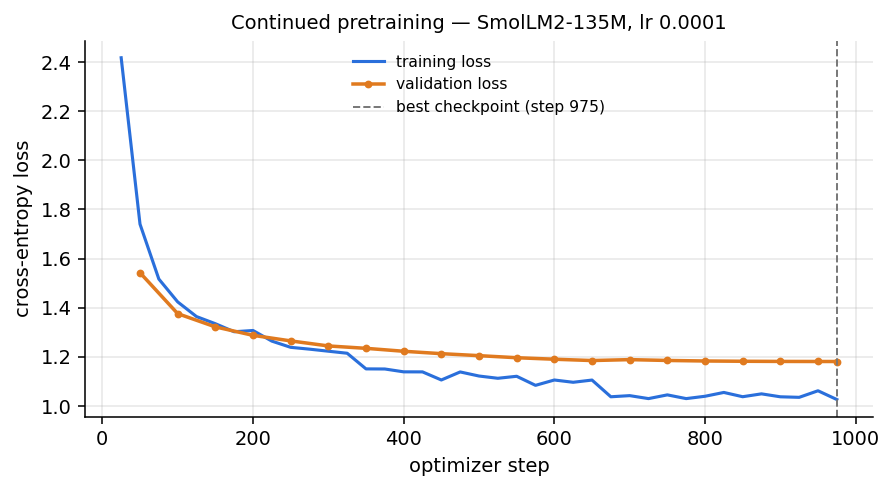

3.00 passes; best validation loss 1.1814 at step 975; 27.9 min


In [13]:
class SaveEachEpoch(TrainerCallback):
    """Saves a checkpoint after every pass over the data."""
    def __init__(self, out_dir, tok):
        self.out_dir, self.tok = Path(out_dir), tok
    def on_epoch_end(self, args, state, control, model=None, **kw):
        d = self.out_dir / f"epoch-{round(state.epoch)}"
        model.save_pretrained(d); self.tok.save_pretrained(d)

def training_args(stage, out_dir, n_train):
    c = CFG[stage]
    steps_per_epoch = math.ceil(n_train / (c["batch_size"] * c["grad_accum"]))
    total_steps = MAX_STEPS if MAX_STEPS > 0 else steps_per_epoch * c["epochs"]
    return TrainingArguments(
        output_dir=str(out_dir), num_train_epochs=c["epochs"], max_steps=MAX_STEPS,
        per_device_train_batch_size=c["batch_size"], per_device_eval_batch_size=c["batch_size"],
        gradient_accumulation_steps=c["grad_accum"], learning_rate=c["lr"], weight_decay=c["weight_decay"],
        warmup_steps=int(c["warmup_ratio"] * total_steps), lr_scheduler_type="cosine", max_grad_norm=1.0,
        eval_strategy="steps", eval_steps=c["eval_steps"], save_strategy="steps", save_steps=c["eval_steps"],
        save_total_limit=2, load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
        logging_steps=max(5, c["eval_steps"] // 2), fp16=torch.cuda.is_available(), report_to="none",
        seed=CFG["seed"], data_seed=CFG["seed"], remove_unused_columns=False, dataloader_num_workers=0)

def plot_history(log_history, best_step, title, path):
    tr = [(x["step"], x["loss"]) for x in log_history if "loss" in x]
    va = [(x["step"], x["eval_loss"]) for x in log_history if "eval_loss" in x]
    fig, ax = plt.subplots(figsize=(6.5, 3.6), dpi=140)
    if tr: ax.plot(*zip(*tr), label="training loss", color="#2a6fdb", lw=1.6)
    if va: ax.plot(*zip(*va), label="validation loss", color="#e07a1f", lw=1.8, marker="o", ms=3)
    if best_step: ax.axvline(best_step, color="#777", ls="--", lw=1, label=f"best checkpoint (step {best_step})")
    ax.set_xlabel("optimizer step"); ax.set_ylabel("cross-entropy loss"); ax.set_title(title, fontsize=10)
    ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(path); plt.show()

train_blocks = pack(train_texts, tokenizer, BS, keep_remainder=False)
val_blocks = pack(val_texts, tokenizer, BS, keep_remainder=True)
if QUICK_TEST:
    val_blocks = val_blocks[:40]
print(f"CPT data: {len(train_blocks)} training blocks x {BS} tokens = {len(train_blocks) * BS:,} tokens per pass; "
      f"{len(val_blocks)} validation blocks")

# Re-use a finished continued-pretraining run of this session (saves ~30 min when only SFT changes)
REUSE_CPT = True
cpt_dir, info_path = CKPT / "cpt", RES / "cpt_info.json"
if REUSE_CPT and not QUICK_TEST and (cpt_dir / "best").exists():
    cpt_model = load_model(str(cpt_dir / "best"))
    if info_path.exists():
        cpt_info = json.load(open(info_path))
    else:   # rebuild the training record from the Trainer's last checkpoint
        states = sorted((cpt_dir / "trainer").glob("checkpoint-*/trainer_state.json"), key=lambda p: int(p.parent.name.split("-")[1]))
        st = json.load(open(states[-1]))
        cpt_info = {"passes": st["epoch"], "best_val_loss": st["best_metric"], "best_step": st.get("best_global_step"),
                    "minutes": None, "log_history": st["log_history"]}
    print("re-using the continued-pretraining checkpoint already trained in this session")
else:
    set_seed(CFG["seed"])
    cpt_trainer = Trainer(model=base_model, args=training_args("cpt", cpt_dir / "trainer", len(train_blocks)),
                          train_dataset=train_blocks, eval_dataset=val_blocks, data_collator=Collator(tokenizer.pad_token_id),
                          callbacks=[EarlyStoppingCallback(CFG["cpt"]["patience"], 0.001), SaveEachEpoch(cpt_dir, tokenizer)])
    t0 = time.time(); cpt_trainer.train()
    cpt_model = cpt_trainer.model                  # best checkpoint (load_best_model_at_end=True)
    cpt_model.save_pretrained(cpt_dir / "best"); tokenizer.save_pretrained(cpt_dir / "best")
    cpt_info = {"passes": cpt_trainer.state.epoch, "best_val_loss": cpt_trainer.state.best_metric,
                "best_step": getattr(cpt_trainer.state, "best_global_step", None), "minutes": (time.time() - t0) / 60,
                "log_history": cpt_trainer.state.log_history}
json.dump(cpt_info, open(info_path, "w"), indent=1)
plot_history(cpt_info["log_history"], cpt_info["best_step"],
             f"Continued pretraining — {CFG['base_model'].split('/')[-1]}, lr {CFG['cpt']['lr']}", FIG / "cpt_loss.png")
print(f"{cpt_info['passes']:.2f} passes; best validation loss {cpt_info['best_val_loss']:.4f} at step {cpt_info['best_step']}"
      + (f"; {cpt_info['minutes']:.1f} min" if cpt_info["minutes"] else ""))

In [14]:
ppl["cpt"] = perplexity(cpt_model, held_blocks)
print(f"held-out perplexity: base {ppl['base']:.3f} -> after continued pretraining {ppl['cpt']:.3f} "
      f"({100 * (1 - ppl['cpt'] / ppl['base']):.1f}% lower)")
samples["after CPT"] = complete(cpt_model, tokenizer, SAMPLE_PROMPTS)
samples.to_csv(RES / "cpt_samples.csv", index=False)
results["cpt"] = run_test_set("cpt", cpt_model, tokenizer)
samples

held-out perplexity: base 14.925 -> after continued pretraining 3.282 (78.0% lower)


,prompt,base,after CPT
0,Gold members get,a lot of money from the government.\n\nThe government is also trying to get the people to vote for them.\n\nThe government is trying to get the people to vo...,"unlimited refunds.\nAgent: I'm sorry, I'm not sure what you mean.\nCustomer: I'm not sure if I understand.\nAgent: I'm sorry, I'm not sure what you mean.\nC..."
1,Bronze members can return an item if,they have not yet paid for it.\n\nThe item can be returned to the owner if the item is not in the possession of the owner.\n\nThe item can be returned to th...,they have not yet received it.\nAgent: Gold members can return an item if they have received it within 6 months. Silver members can return an item if they h...
2,"To initiate a refund, the agent asks the customer for",a receipt. The receipt is then sent to the customer’s bank account. The customer’s bank account is then used to pay the refund amount.\n\nThe refund process...,"their full name or account ID, then the order ID, then the email address, then the username, then the password, then the order ID, then the email address, t..."
3,"Customer support conversation.\nCustomer: hi, my promo code is not working.\nAgent:","ok, let me check it.\nCustomer: ok, let me check it.\nAgent: ok, let me check it.\nCustomer: ok, let me check it.\nAgent: ok, let me check it.\nCustomer:","Hello, how can I help you today?\nCustomer: I'm trying to order something but my promo code keeps saying it's invalid\nAgent: I'm sorry to hear that. Let me..."
4,The refund status can be,"changed by clicking on the ""Refund"" button.\n\nThe refund status can be changed by clicking on the ""Refund"" button.\n\nThe refund status can be changed by c...","changed by checking the status of the refund.\n- If the refund is not in progress, the status is 'In Progress'\n- If the refund is complete, the status is '..."


## 6. Stage 2 — supervised fine-tuning (SFT)
Starts from the best continued-pretraining checkpoint. Each pair becomes `prompt + answer + <eos>`; prompt tokens get
the label **-100**, so the loss is computed **on the answer only** (the cell below prints one example token by token).
10% of the pairs are kept for validation, split by paraphrase group so the same fact is never on both sides.

In [15]:
def encode_pair(p, tok, max_len):
    prompt = build_prompt(p["history"], p["question"])
    p_ids = tok(prompt)["input_ids"]
    a_ids = tok(" " + p["answer"].strip(), add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    p_ids = p_ids[-(max_len - len(a_ids)):]                      # keep the end of a long prompt
    return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}

groups = sorted({p["group"] for p in pairs}); random.Random(CFG["seed"]).shuffle(groups)
val_groups = set(groups[:round(CFG["sft"]["val_frac"] * len(groups))])
sft_train = [encode_pair(p, tokenizer, CFG["sft"]["max_len"]) for p in pairs if p["group"] not in val_groups]
sft_val = [encode_pair(p, tokenizer, CFG["sft"]["max_len"]) for p in pairs if p["group"] in val_groups]
n_loss = sum(sum(l != -100 for l in e["labels"]) for e in sft_train); n_all = sum(len(e["labels"]) for e in sft_train)
print(f"SFT: {len(sft_train)} train / {len(sft_val)} validation pairs; loss on {n_loss:,} of {n_all:,} tokens "
      f"({100 * n_loss / n_all:.0f}%) = answers + <eos>")

ex = encode_pair(next(p for p in pairs if p["category"] == "scenario"), tokenizer, 512)
pd.DataFrame({"token": [tokenizer.decode([t]) for t in ex["input_ids"]],
              "in the loss?": ["IGNORED (-100)" if l == -100 else "LOSS" for l in ex["labels"]]}).T

SFT: 533 train / 58 validation pairs; loss on 17,945 of 30,726 tokens (58%) = answers + <eos>


,0,1,2,3,4,5,6,7,8,9,...,38,39,40,41,42,43,44,45,46,47
token,Customer,support,conversation,.,\n,Customer,:,I,'m,a,...,when,they,are,only,,1,day,late,.,<|endoftext|>
in the loss?,IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),IGNORED (-100),...,LOSS,LOSS,LOSS,LOSS,LOSS,LOSS,LOSS,LOSS,LOSS,LOSS


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss
10,1.570710,1.261991
20,1.109973,0.945039
30,0.723800,0.850855
40,0.795641,0.799640
50,0.658026,0.798951
60,0.844418,0.752453
70,0.805112,0.743196
80,0.381551,0.752688
90,0.386482,0.747066
100,0.306468,0.745537


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (14 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

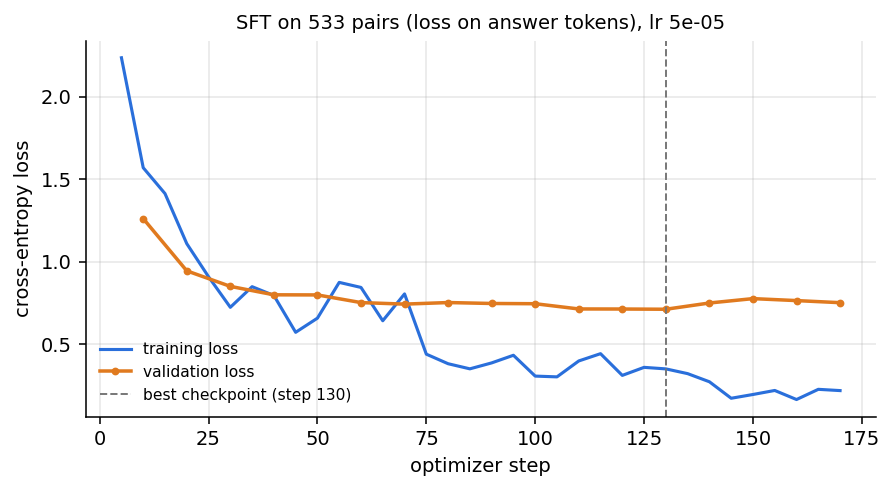

2.54 passes; best validation loss 0.7121 at step 130


,test_id,model_answer,score,stopped
0,SP-01,"Yes. The agent can send a shipping label with the correct measurements, and the customer can return the jeans by mail, in store, or at a drop-off center.",0.0,True
1,SP-02,"I'm sorry, but that is outside what AcmeCorp customer support can help with. I can help with your orders, account, shipping, subscription, refunds or returns.",1.0,True
2,SP-03,"The warranty period is 12 months from the date you purchase or receive the product, and 30 days after that.",0.0,True
3,SP-04,"I can check your refund status. First, could you please give me your full name or account ID?",1.0,True
4,SP-05,"I'm sorry, but I don't have that information in our support guidelines. The guidelines only say this is answered in the return policy handbook, and that art...",0.0,True
5,SP-06,No. Guests are only allowed 7 days.,0.0,True
6,SP-07,"The refund methods are by gift card, add value to the account, paper check or credit card.",1.0,True
7,SP-08,No. Silver returns must be within 6 months.,0.0,True
8,SP-09,"$130, which is the standard refund amount.",1.0,True
9,SP-10,The refund is offered when the customer is only charged for part of the purchase.,0.0,True


In [16]:
# Re-use the SFT model already trained in this session on the same pairs (keeps the graded answers identical)
REUSE_SFT = True
sft_dir, sft_info_path = CKPT / "sft", RES / "sft_info.json"
pairs_id = f"{len(pairs)}-{sum(len(p['answer']) for p in pairs)}"          # fingerprint of the SFT data
old = json.load(open(sft_info_path)) if sft_info_path.exists() else None
if old is None and (RES / "run_summary.json").exists():                    # run of an earlier notebook version
    prev = json.load(open(RES / "run_summary.json")).get("sft", {})
    states = sorted((sft_dir / "trainer").glob("checkpoint-*/trainer_state.json"), key=lambda p: int(p.parent.name.split("-")[1]))
    if prev.get("pairs") == len(pairs) and states:
        st = json.load(open(states[-1]))
        old = {"pairs_id": pairs_id, "passes": prev.get("passes", st["epoch"]), "best_val_loss": st["best_metric"],
               "best_step": st.get("best_global_step"), "minutes": prev.get("minutes"), "log_history": st["log_history"]}
if REUSE_SFT and not QUICK_TEST and (sft_dir / "best").exists() and old and old.get("pairs_id") == pairs_id:
    sft_model, sft_info = load_model(str(sft_dir / "best")), old
    print("re-using the SFT checkpoint already trained in this session on the same pairs")
else:
    set_seed(CFG["seed"])
    sft_model = load_model(str(cpt_dir / "best"))
    sft_trainer = Trainer(model=sft_model, args=training_args("sft", sft_dir / "trainer", len(sft_train)),
                          train_dataset=sft_train, eval_dataset=sft_val, data_collator=Collator(tokenizer.pad_token_id),
                          callbacks=[EarlyStoppingCallback(CFG["sft"]["patience"], 0.001), SaveEachEpoch(sft_dir, tokenizer)])
    t0 = time.time(); sft_trainer.train()
    sft_model = sft_trainer.model
    sft_model.save_pretrained(sft_dir / "best"); tokenizer.save_pretrained(sft_dir / "best")
    sft_info = {"pairs_id": pairs_id, "passes": sft_trainer.state.epoch, "best_val_loss": sft_trainer.state.best_metric,
                "best_step": getattr(sft_trainer.state, "best_global_step", None), "minutes": (time.time() - t0) / 60,
                "log_history": sft_trainer.state.log_history}
json.dump(sft_info, open(sft_info_path, "w"), indent=1)
plot_history(sft_info["log_history"], sft_info["best_step"],
             f"SFT on {len(sft_train)} pairs (loss on answer tokens), lr {CFG['sft']['lr']}", FIG / "sft_loss.png")
print(f"{sft_info['passes']:.2f} passes; best validation loss {sft_info['best_val_loss']:.4f} at step {sft_info['best_step']}")

ppl["sft"] = perplexity(sft_model, held_blocks)
results["sft"] = run_test_set("sft", sft_model, tokenizer)
results["sft"][["test_id", "model_answer", "score", "stopped"]].head(10)

## 7. Scoreboard
Same test set, same prompt, same generation settings for every version. Until §8 is done, the longer answers carry
*provisional* rubric scores; after the human grades are merged, re-run this cell.

In [17]:
NAMES = {"base": "Small model, base", "cpt": "+ continued pretraining", "sft": "+ SFT"}

def summarize(df):
    ref = df[df.expected_action == "ABSTAIN"]; ans = df[df.expected_action != "ABSTAIN"]
    return {"accuracy": df.score.mean(), "refusal_accuracy": (ref.score >= 1).mean() if len(ref) else float("nan"),
            "over_refusal": ans.refused.mean() if len(ans) else float("nan"),
            "stopped_cleanly": df.stopped.mean(), "latency_s": df.latency_s.mean(),
            "human_graded": int((df.score_source == "human").sum()),
            "provisional": int((df.score_source == "provisional").sum())}

def make_scoreboard():
    notes = {"base": f"`{CFG['base_model']}`, no training",
             "cpt": f"{cpt_info['passes']:.1f} passes, lr {CFG['cpt']['lr']}, {BS}-token blocks, policy docs x{CFG['data']['policy_upsample']}",
             "sft": f"{len(pairs)} pairs ({len(sft_train)}/{len(sft_val)}), {sft_info['passes']:.1f} passes, lr {CFG['sft']['lr']}, loss on answers only"}
    rows = []
    for k in ["base", "cpt", "sft"]:
        s = summarize(results[k])
        status = "human-graded" if s["provisional"] == 0 else f"PROVISIONAL ({s['provisional']} answers not yet hand-graded)"
        rows.append({"Version": NAMES[k], "Held-out perplexity": round(ppl[k], 2), "Accuracy": f"{100 * s['accuracy']:.1f}%",
                     "Refusal accuracy": f"{100 * s['refusal_accuracy']:.1f}%", "Avg. latency (s)": round(s["latency_s"], 2),
                     "Notes": f"{notes[k]}; {status}"})
    board = pd.DataFrame(rows)
    md = ["# Scoreboard", "", f"Same test set for every version: `tests/test_questions.csv` ({len(results['base'])} cases, "
          f"{int((results['base'].expected_action == 'ABSTAIN').sum())} should be refused). Greedy decoding, max "
          f"{CFG['gen']['max_new_tokens']} new tokens, identical prompt for all models. Accuracy = mean score (exact match for "
          "short answers, 1/0.5/0 hand grades for longer ones). Refusal accuracy = share of should-refuse cases declined. "
          "Perplexity on the 10% held-out documents. Latency = mean generation time per answer on a T4 GPU.", "",
          "| " + " | ".join(board.columns) + " |", "|" + "---|" * len(board.columns)]
    md += ["| " + " | ".join(str(v) for v in r) + " |" for r in board.values]
    (WORK / "SCOREBOARD.md").write_text("\n".join(md) + "\n")
    json.dump({k: {**summarize(results[k]), "perplexity": ppl[k]} for k in results}, open(RES / "summary.json", "w"), indent=2)
    return board

board = make_scoreboard()
board

,Version,Held-out perplexity,Accuracy,Refusal accuracy,Avg. latency (s),Notes
0,"Small model, base",14.93,28.3%,0.0%,0.58,"`HuggingFaceTB/SmolLM2-135M`, no training; PROVISIONAL (18 answers not yet hand-graded)"
1,+ continued pretraining,3.28,5.0%,0.0%,0.63,"3.0 passes, lr 0.0001, 512-token blocks, policy docs x5; PROVISIONAL (18 answers not yet hand-graded)"
2,+ SFT,4.52,40.0%,16.7%,1.11,"591 pairs (533/58), 2.5 passes, lr 5e-05, loss on answers only; PROVISIONAL (18 answers not yet hand-graded)"


In [ ]:
# The same three test questions answered by all three models (for the report)
SHOW = ["SP-06", "SP-12", "SP-25"]
pd.DataFrame([{"test_id": t, "question": results["base"].set_index("test_id").loc[t, "question"],
               **{NAMES[k]: results[k].set_index("test_id").loc[t, "model_answer"][:200] for k in results}}
              for t in SHOW if t in set(results["base"].test_id)])

## 8. Human grading (two graders, independently)
**8a.** Export one blind sheet per grader: all longer answers of the three models, shuffled, model names hidden
(the key is kept separately). Each grader fills `grade` (1 / 0.5 / 0) **alone**. Refusal cases are 1 or 0 only.
(Our filled first-round sheets are in `data/grading/`; the blank sheets are only needed if answers change.)

In [18]:
from openpyxl.styles import Alignment, Font, PatternFill

judged = pd.concat([results[k].assign(model=k) for k in results])
judged = judged[judged.answer_type != "exact"].sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
judged["item_id"] = [f"item-{i + 1:03d}" for i in range(len(judged))]
judged[["item_id", "model", "test_id"]].to_csv(RES / "grading/key_do_not_open_while_grading.csv", index=False)
sheet = judged[["item_id", "test_id", "conversation_history", "question", "expected_answer", "model_answer"]].assign(grade="", comment="")
sheet = sheet.sort_values(["test_id", "item_id"])
for g in ["A", "B"]:
    path = RES / f"grading/grader_{g}_blank.xlsx"
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        sheet.to_excel(xw, index=False, sheet_name="grading")
        ws = xw.sheets["grading"]
        for col, w in zip("ABCDEFGH", [10, 8, 28, 35, 40, 65, 8, 30]):
            ws.column_dimensions[col].width = w
        for row in ws.iter_rows():
            for cell in row:
                cell.alignment = Alignment(wrap_text=True, vertical="top")
        for cell in ws[1]:
            cell.font = Font(bold=True)
        for cell in ws["G"]:
            cell.fill = PatternFill("solid", fgColor="FFF2CC")
        ws.freeze_panes = "A2"
print(f"{len(sheet)} answers to grade -> {RES / 'grading'}/grader_A_blank.xlsx and grader_B_blank.xlsx")

54 answers to grade -> /kaggle/working/results/grading/grader_A_blank.xlsx and grader_B_blank.xlsx


**8b. First round.** Our two graders graded the 54 answers independently (`data/grading/grader_A_round1.xlsx`,
`grader_B_round1.xlsx`). Agreement and Cohen's κ are computed on these files, before any discussion.

In [19]:
def find_upload(tag):
    hits = [p for p in list(Path("/kaggle/input").glob("**/*.xlsx")) + list(RES.rglob("*.xlsx"))
            if tag in p.name and "blank" not in p.name]
    return sorted(hits)[-1] if hits else None

def read_grades(path):
    d = pd.read_excel(path, dtype=str).fillna("")
    d["grade"] = d["grade"].str.replace(",", ".").str.strip().astype(float)
    assert d.grade.isin([0, 0.5, 1]).all(), f"{path.name}: grades must be 0, 0.5 or 1"
    return d.set_index("item_id")

def cohen_kappa(a, b):
    po = (a == b).mean()
    pe = sum((a == c).mean() * (b == c).mean() for c in [0, 0.5, 1])
    return 1.0 if pe == 1 else (po - pe) / (1 - pe)

fa, fb = PROJECT / "data/grading/grader_A_round1.xlsx", PROJECT / "data/grading/grader_B_round1.xlsx"
A, B = read_grades(fa), read_grades(fb)
B = B.loc[A.index]
agree = A.grade == B.grade
grading_stats = {"items": len(A), "agreed": int(agree.sum()), "agreement": agree.mean(),
                 "cohen_kappa": cohen_kappa(A.grade, B.grade)}
json.dump(grading_stats, open(RES / "grading/agreement.json", "w"), indent=2)
print(f"first-round agreement: {grading_stats['agreed']}/{grading_stats['items']} = {100 * grading_stats['agreement']:.1f}% "
      f"| Cohen's kappa = {grading_stats['cohen_kappa']:.3f}")

first-round agreement: 49/54 = 90.7% | Cohen's kappa = 0.742


**8c. Final grades.** (1) The 5 disagreements were settled together, following the rubric (`FINAL`).
(2) All 54 grades were then re-checked against the rubric: 5 grades did not follow it and were
corrected (`RUBRIC_REVIEW`): item-053 is a refusal case, so 0 or 1 only (0.5 → 0); four answers that gave every
required point had been graded too strictly (→ 1, and 0 → 0.5 for item-005). No grade was changed for any other reason.

The grades belong to the answers that were graded. If a re-run produces a different answer for an item, that item is
**not** given the old grade; it is listed so it can be graded again with the blank sheets of 8a.

In [20]:
FINAL = {"item-040": 1, "item-004": 0.5, "item-022": 1, "item-015": 0, "item-024": 0}
RUBRIC_REVIEW = {"item-053": 0, "item-037": 1, "item-033": 1, "item-043": 1, "item-005": 0.5}

disagreements = A[~agree][["test_id", "question", "model_answer"]].assign(
    grade_A=A.grade[~agree], grade_B=B.grade[~agree], comment_A=A.comment[~agree], comment_B=B.comment[~agree])
disagreements["final"] = disagreements.index.map(FINAL)
assert disagreements["final"].notna().all(), "every disagreement needs a FINAL grade"
disagreements.to_excel(RES / "grading/disagreements.xlsx")
display(disagreements[["test_id", "grade_A", "grade_B", "final"]])

final = A.grade.where(agree, pd.Series(FINAL)).astype(float)
final.update(pd.Series(RUBRIC_REVIEW, dtype=float))
key = pd.read_csv(RES / "grading/key_do_not_open_while_grading.csv").set_index("item_id")
final = final[final.index.isin(key.index)]                         # (QUICK_TEST answers only a few questions)
pd.DataFrame({"model": key.model, "test_id": key.test_id, "grade_A": A.grade, "grade_B": B.grade,
              "final": final, "rubric_review": pd.Series(RUBRIC_REVIEW)}).dropna(subset=["model"]).to_csv(RES / "grading/final_grades.csv")

auto_results = {k: df.copy() for k, df in results.items()}      # automatic scores, kept for comparison
same_text = lambda x, y: re.sub(r"\s+", " ", str(x)).strip().lower() == re.sub(r"\s+", " ", str(y)).strip().lower()
changed = []
for item, g in final.items():
    k, t = key.loc[item, "model"], key.loc[item, "test_id"]
    row = results[k].test_id == t
    if row.sum() == 0:
        continue
    if same_text(results[k].loc[row, "model_answer"].iloc[0], A.loc[item, "model_answer"]):
        results[k].loc[row, ["score", "score_source"]] = [g, "human"]
    else:
        changed.append(item)
print(f"human grades applied to {len(final) - len(changed)} of {len(final)} answers")
if changed:
    print(f"{len(changed)} answers differ from the graded ones in this run -> grade them again (8a sheets): {changed}")
for k in results:
    results[k].to_csv(RES / f"results_{k}.csv", index=False)
board = make_scoreboard()
display(board)

,test_id,grade_A,grade_B,final
item_id,,,,
item-040,SP-04,1.0,0.5,1.0
item-004,SP-22,0.0,0.5,0.5
item-022,SP-26,1.0,0.5,1.0
item-015,SP-27,0.0,0.5,0.0
item-024,SP-27,0.0,0.5,0.0


human grades applied to 54 of 54 answers


,Version,Held-out perplexity,Accuracy,Refusal accuracy,Avg. latency (s),Notes
0,"Small model, base",14.93,31.7%,16.7%,0.58,"`HuggingFaceTB/SmolLM2-135M`, no training; human-graded"
1,+ continued pretraining,3.28,8.3%,0.0%,0.63,"3.0 passes, lr 0.0001, 512-token blocks, policy docs x5; human-graded"
2,+ SFT,4.52,38.3%,16.7%,1.11,"591 pairs (533/58), 2.5 passes, lr 5e-05, loss on answers only; human-graded"


In [21]:
# Automatic (keyword) scoring vs. human grading, and where each model's points come from
compare = pd.DataFrame([{"model": NAMES[k], "automatic": f"{100 * auto_results[k].score.mean():.1f}%",
                         "human-graded (official)": f"{100 * results[k].score.mean():.1f}%"} for k in results])
rows = []
for k, df in results.items():
    ex, ju = df[df.answer_type == "exact"], df[df.answer_type != "exact"]
    yn = ex[ex.test_id.isin(tests[tests.gold_short.isin(["yes", "no"])].test_id)]
    rows.append({"model": NAMES[k], "exact (12)": f"{ex.score.sum():.0f}/12", "of which yes/no (10)": f"{yn.score.sum():.0f}/10",
                 "answers starting with 'yes'": int(yn.model_answer.str.lower().str.startswith("yes").sum()),
                 "hand-graded (18)": f"{ju.score.sum():.1f}/18", "total (30)": f"{df.score.sum():.1f}/30"})
breakdown = pd.DataFrame(rows)
compare.to_csv(RES / "auto_vs_human.csv", index=False); breakdown.to_csv(RES / "accuracy_breakdown.csv", index=False)
display(compare); display(breakdown)

,model,automatic,human-graded (official)
0,"Small model, base",28.3%,31.7%
1,+ continued pretraining,5.0%,8.3%
2,+ SFT,40.0%,38.3%


,model,exact (12),of which yes/no (10),answers starting with 'yes',hand-graded (18),total (30)
0,"Small model, base",8/12,8/10,8,1.5/18,9.5/30
1,+ continued pretraining,0/12,0/10,2,2.5/18,2.5/30
2,+ SFT,6/12,5/10,4,5.5/18,11.5/30


## 9. Error analysis (SFT model)
Every SFT answer below full marks gets **one** cause. The rule: the cause is what made the answer wrong.
* **format failure** — no usable answer because of the format (empty, endless repetition, broken text);
* **refusal error** — refuses an answerable question, or answers one it should refuse;
* **hallucination** — a fluent answer that states facts not in the guidelines (numbers, rules, approvals);
* **knowledge missing** — the fact is in the documents but the model did not produce or apply it;
* **test-case problem** — the expected answer itself is unclear or wrong.

The cell suggests a cause; the team reads every row in `error_analysis.xlsx`, corrects `final_cause`, uploads it, and
the counts are recomputed.

19 SFT answers below full marks; suggested causes (review them!); 0 of 30 SFT answers did not end with <eos>


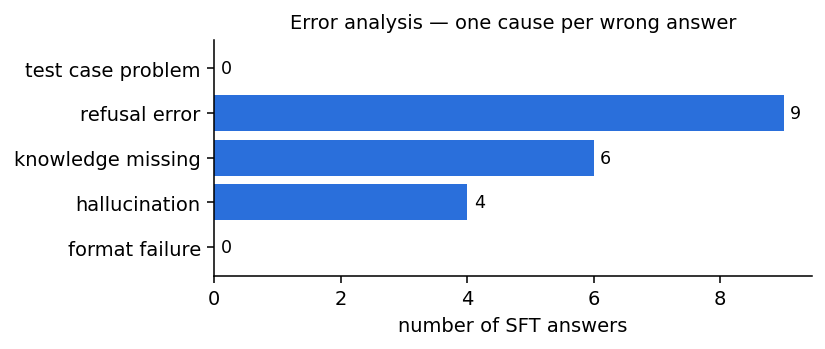

,test_id,score,final_cause,evidence
0,SP-01,0.0,knowledge_missing,documented fact not produced or not applied
2,SP-03,0.0,refusal_error,answered a question it should decline
4,SP-05,0.0,refusal_error,declined an answerable question
5,SP-06,0.0,hallucination,states 7
7,SP-08,0.0,hallucination,states 6
9,SP-10,0.0,knowledge_missing,documented fact not produced or not applied
11,SP-12,0.0,knowledge_missing,documented fact not produced or not applied
15,SP-16,0.5,knowledge_missing,documented fact not produced or not applied
17,SP-18,0.0,hallucination,states 7
18,SP-19,0.0,refusal_error,declined an answerable question


In [22]:
CAUSES = ["format_failure", "hallucination", "knowledge_missing", "refusal_error", "test_case_problem"]
FACT_RX = re.compile(r"\$?\d+(?:\.\d+)?|\b(?:gold|silver|bronze|guest)\b|\b(?:days?|months?|weeks?|years?)\b", re.I)

def suggest_cause(r):
    a = str(r.model_answer)
    words = a.split()
    rep = 1 - len(set(zip(words, words[1:], words[2:]))) / max(len(words) - 2, 1)
    letters = sum(ch.isalpha() for ch in a) / max(len(a), 1)
    if len(words) < 3 or rep > 0.5 or letters < 0.5:
        return "format_failure", f"{len(words)} words, repetition {rep:.2f}"
    if r.expected_action == "ABSTAIN" and not r.refused:
        return "refusal_error", "answered a question it should decline"
    if r.expected_action != "ABSTAIN" and r.refused:
        return "refusal_error", "declined an answerable question"
    ctx = " ".join([r.question, str(r.conversation_history), r.expected_answer]).lower()
    invented = sorted({m.group(0).lower() for m in FACT_RX.finditer(a) if m.group(0).lower() not in ctx})
    if invented:
        return "hallucination", "states " + ", ".join(invented[:5])
    return "knowledge_missing", "documented fact not produced or not applied"

errors = results["sft"][results["sft"].score < 1].copy()
errors[["suggested_cause", "evidence"]] = errors.apply(lambda r: pd.Series(suggest_cause(r)), axis=1)
errors["final_cause"] = errors.suggested_cause; errors["reviewer_note"] = ""
errors[["test_id", "question", "expected_answer", "model_answer", "score", "suggested_cause", "evidence",
        "final_cause", "reviewer_note"]].to_excel(RES / "error_analysis.xlsx", index=False)

reviewed = find_upload("error_analysis_reviewed")
if reviewed:
    errors = pd.read_excel(reviewed).fillna("")
    assert errors.final_cause.isin(CAUSES).all(), f"final_cause must be one of {CAUSES}"
counts = errors.final_cause.value_counts().reindex(CAUSES, fill_value=0)
json.dump({"failures": len(errors), "counts": counts.to_dict(), "reviewed_by_hand": bool(reviewed)},
          open(RES / "error_counts.json", "w"), indent=2)
print(f"{len(errors)} SFT answers below full marks; {'reviewed by hand' if reviewed else 'suggested causes (review them!)'}; "
      f"{int((~results['sft'].stopped).sum())} of {len(results['sft'])} SFT answers did not end with <eos>")
fig, ax = plt.subplots(figsize=(6, 2.6), dpi=140)
ax.barh([c.replace("_", " ") for c in CAUSES], counts.values, color="#2a6fdb")
for i, v in enumerate(counts.values): ax.text(v + 0.1, i, str(v), va="center", fontsize=9)
ax.set_xlabel("number of SFT answers"); ax.set_title("Error analysis — one cause per wrong answer", fontsize=10)
ax.spines[["top", "right"]].set_visible(False); fig.tight_layout(); fig.savefig(FIG / "error_causes.png"); plt.show()
errors[["test_id", "score", "final_cause", "evidence"]]

## 10. Save everything
Results, figures and the scoreboard are zipped for download. Checkpoints stay in `checkpoints/` (≈0.5 GB each);
set `PUSH_TO_HUB = True` and add an `HF_TOKEN` secret to upload the two best checkpoints to private Hub repos.

In [23]:
json.dump({"config": CFG, "corpus": corpus_stats.to_dict("records"), "perplexity": ppl,
           "cpt": {k: v for k, v in cpt_info.items() if k != "log_history"},
           "sft": {"passes": sft_info["passes"], "best_val_loss": sft_info["best_val_loss"], "minutes": sft_info["minutes"],
                   "pairs": len(pairs), "train": len(sft_train), "val": len(sft_val)}},
          open(RES / "run_summary.json", "w"), indent=2, default=str)
import zipfile
with zipfile.ZipFile(WORK / "phase2_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in [WORK / "SCOREBOARD.md", *RES.rglob("*"), *FIG.glob("*")]:
        if p.is_file():
            z.write(p, p.relative_to(WORK))
print("download:", WORK / "phase2_results.zip")

PUSH_TO_HUB, HUB_USER = False, "your-hf-username"
if PUSH_TO_HUB:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass
    for stage, model in [("cpt", cpt_model), ("sft", sft_model)]:
        model.push_to_hub(f"{HUB_USER}/abcd-smollm2-{stage}", private=True)
        tokenizer.push_to_hub(f"{HUB_USER}/abcd-smollm2-{stage}", private=True)

download: /kaggle/working/phase2_results.zip


## 11. Numbers for the report
Everything the report needs, in one place.

In [24]:
report_numbers = {
    "corpus": corpus_stats.to_dict("records"),
    "perplexity": {k: round(v, 3) for k, v in ppl.items()},
    "cpt": {k: v for k, v in cpt_info.items() if k != "log_history"},
    "sft": {"pairs": len(pairs), "train": len(sft_train), "val": len(sft_val), "passes": sft_info["passes"],
            "best_val_loss": sft_info["best_val_loss"]},
    "grading": grading_stats,
    "accuracy (human)": {NAMES[k]: f"{100 * results[k].score.mean():.1f}%" for k in results},
    "accuracy (automatic)": {NAMES[k]: f"{100 * auto_results[k].score.mean():.1f}%" for k in results},
    "refusal accuracy": {NAMES[k]: f"{100 * summarize(results[k])['refusal_accuracy']:.1f}%" for k in results},
    "error causes (SFT)": counts.to_dict(),
}
json.dump(report_numbers, open(RES / "report_numbers.json", "w"), indent=2, default=str)
with zipfile.ZipFile(WORK / "phase2_results.zip", "w", zipfile.ZIP_DEFLATED) as z:      # refresh the archive
    for p in [WORK / "SCOREBOARD.md", *RES.rglob("*"), *FIG.glob("*")]:
        if p.is_file():
            z.write(p, p.relative_to(WORK))
print(json.dumps(report_numbers, indent=2, default=str)[:4000])

{
  "corpus": [
    {
      "split": "train (unique documents)",
      "documents": 8628,
      "tokens": 2565680
    },
    {
      "split": "train (policy docs x5)",
      "documents": 8996,
      "tokens": 2658960
    },
    {
      "split": "validation (early stopping)",
      "documents": 502,
      "tokens": 150862
    },
    {
      "split": "held-out 10% (perplexity)",
      "documents": 1010,
      "tokens": 302157
    }
  ],
  "perplexity": {
    "base": 14.925,
    "cpt": 3.282,
    "sft": 4.519
  },
  "cpt": {
    "passes": 3.0,
    "best_val_loss": 1.181400179862976,
    "best_step": 975,
    "minutes": 27.903042562802632
  },
  "sft": {
    "pairs": 591,
    "train": 533,
    "val": 58,
    "passes": 2.5373134328358207,
    "best_val_loss": 0.71206134557724
  },
  "grading": {
    "items": 54,
    "agreed": 49,
    "agreement": 0.9074074074074074,
    "cohen_kappa": 0.7421203438395416
  },
  "accuracy (human)": {
    "Small model, base": "31.7%",
    "+ continued pretrain